# STAR Project – Grade 5 Drop

In `01_explore_data` we saw that a lot fewer students have test scores in grade 5 than in grade 4 or grade 6.
In this notebook I check why this happens, and if it is a problem for our question
(does the small class effect last over time?).

The user guide says the grade 5 data was not fully matched with the Tennessee state records,
so maybe the students did not really leave the study. Let's check that.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings("ignore")

df = pd.read_spss("../data/raw/STAR_Students.sav")
print(df.shape)

grades = ["gk", "g1", "g2", "g3", "g4", "g5", "g6", "g7", "g8"]
k3 = ["gk", "g1", "g2", "g3"]

(11601, 379)


New columns I need (from the K–3 years, when the experiment ran):
- `first_classtype` – class type in the first grade the student was in the study (like in notebook 01)
- `small` – 1 = small class, 0 = regular or regular + aide
- `first_school` – school in that first grade
- `freelunch`, `urban` – first value we have in K–3
- `in_g4`, `in_g5`, `in_g6`, `in_g8` – 1 if the student has test data in that grade

In [2]:
df["first_classtype"] = df[[g + "classtype" for g in k3]].astype(object).bfill(axis=1).iloc[:, 0]
df["first_school"] = df[[g + "schid" for g in k3]].bfill(axis=1).iloc[:, 0]
df["freelunch"] = df[[g + "freelunch" for g in k3]].astype(object).bfill(axis=1).iloc[:, 0]
df["urban"] = df[[g + "surban" for g in k3]].astype(object).bfill(axis=1).iloc[:, 0]

df["small"] = (df["first_classtype"] == "SMALL CLASS").astype(int)

# flagg = "achievement data available" in that grade
for g in ["4", "5", "6", "8"]:
    df["in_g" + g] = (df["flagg" + g] == "YES").astype(int)

df = df.copy()
df[["first_classtype", "small", "first_school", "freelunch", "urban", "in_g4", "in_g5", "in_g6"]].head()

,first_classtype,small,first_school,freelunch,urban,in_g4,in_g5,in_g6
0,REGULAR + AIDE CLASS,0,170295.0,FREE LUNCH,RURAL,1,1,0
1,REGULAR + AIDE CLASS,0,169229.0,NON-FREE LUNCH,SUBURBAN,0,0,1
2,REGULAR + AIDE CLASS,0,205492.0,NaN,SUBURBAN,1,0,1
3,REGULAR CLASS,0,257899.0,NON-FREE LUNCH,RURAL,1,0,1
4,REGULAR + AIDE CLASS,0,244796.0,FREE LUNCH,INNER CITY,1,0,1


## 2. How big is the drop?

Number of students with a math score and a reading score in each grade, and number of schools.

In [3]:
counts = pd.DataFrame({
    "math": [df[g + "tmathss"].notna().sum() for g in grades],
    "reading": [df[g + "treadss"].notna().sum() for g in grades],
    "schools": [df[g + "schid"].nunique() for g in grades],
}, index=grades)
counts

,math,reading,schools
gk,5871,5789,79
g1,6598,6395,76
g2,6065,6077,75
g3,6077,6000,75
g4,4331,6005,76
g5,2589,2591,56
g6,6422,6428,525
g7,4888,4906,181
g8,6213,6224,406


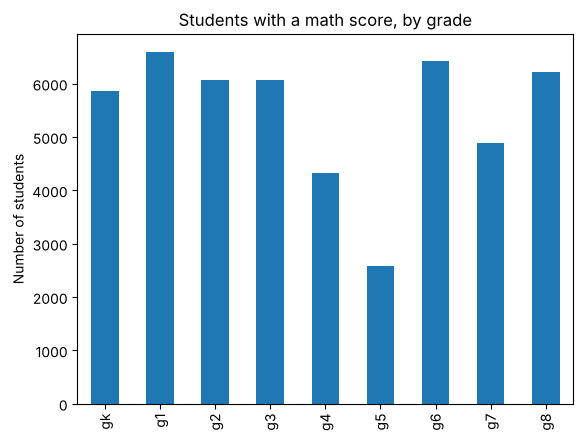

Grade 5 vs grade 4: 40 % fewer


In [4]:
counts["math"].plot(kind="bar", title="Students with a math score, by grade")
plt.ylabel("Number of students")
plt.savefig("../figures/grade5_students_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()

print("Grade 5 vs grade 4:", round((1 - counts.loc["g5", "math"] / counts.loc["g4", "math"]) * 100), "% fewer")

What we found:
- Grade 5 has about 2,600 students with scores, around 40% fewer than grade 4.
- Math and reading drop together, so the whole grade 5 record is missing, not just one test.
- The number of schools also drops (76 in grade 4, 56 in grade 5).
- Grade 6 goes back up, with a lot more schools (grade 6 is in middle schools all over the state).

## 3. Did the students leave, or are the records just missing?

If students left the study, they should also be missing in grade 6.
If it's just missing records, many of them should come back in grade 6.

I take all students with grade 4 data and check if they have data in grades 5 and 6.

In [5]:
g4 = df[df["in_g4"] == 1].copy()

g4["pattern"] = (g4["in_g5"].map({1: "in g5", 0: "not in g5"}) + ", "
                 + g4["in_g6"].map({1: "in g6", 0: "not in g6"}))

g4["pattern"].value_counts()

pattern
not in g5, in g6        2454
in g5, in g6            2292
not in g5, not in g6    1292
in g5, not in g6         301
Name: count, dtype: int64

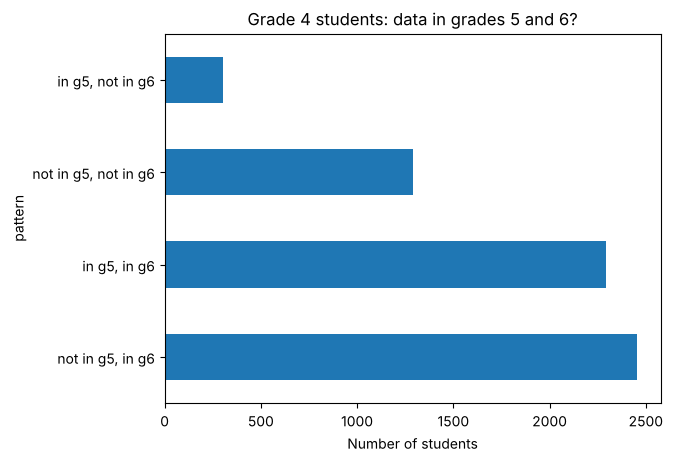

In [6]:
g4["pattern"].value_counts().plot(kind="barh", title="Grade 4 students: data in grades 5 and 6?")
plt.xlabel("Number of students")
plt.savefig("../figures/grade5_patterns.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
missing = g4[g4["in_g5"] == 0]
print("Students with grade 4 data but no grade 5 data:", len(missing))
print("Back in grade 6:", round(missing["in_g6"].mean() * 100), "%")
print("Have grade 8 data:", round(missing["in_g8"].mean() * 100), "%")

Students with grade 4 data but no grade 5 data: 3746
Back in grade 6: 66 %
Have grade 8 data: 64 %


What we found:
- About two thirds of the students who are missing in grade 5 come back in grade 6.
- "Not in g5, in g6" is actually the biggest group, bigger than the students who have all three grades.
- Very few students are in grade 5 and then gone in grade 6.
- So most of the drop is missing records, not students leaving. This fits what the user guide says.

## 4. Which schools?

If the problem was matching files with the state, I expect it to happen by school.
For each grade 4 school: what % of its students have grade 5 data?

In [8]:
school_share = g4.groupby("g4schid")["in_g5"].mean()

print("Grade 4 schools:", len(school_share))
print("Schools with NO grade 5 data:", (school_share == 0).sum())
print("Schools where ALL students have grade 5 data:", (school_share == 1).sum())

zero_schools = school_share[school_share == 0].index
print("Students in the schools with no data:", g4["g4schid"].isin(zero_schools).sum())

Grade 4 schools: 76
Schools with NO grade 5 data: 22
Schools where ALL students have grade 5 data: 0
Students in the schools with no data: 1070


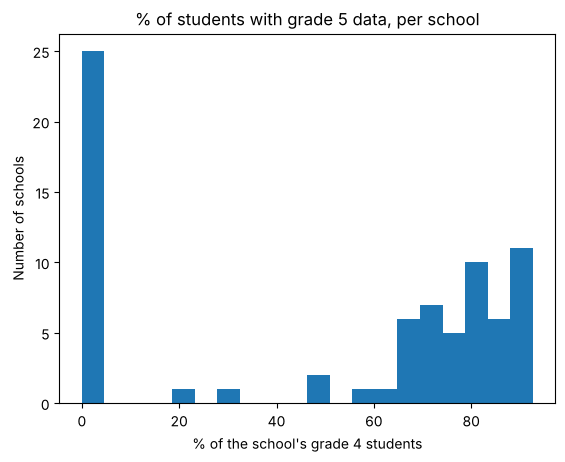

In [9]:
(school_share * 100).plot(kind="hist", bins=20, title="% of students with grade 5 data, per school")
plt.xlabel("% of the school's grade 4 students")
plt.ylabel("Number of schools")
plt.savefig("../figures/grade5_by_school.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# students who have grade 5 data - are they in the same school as in grade 4?
has_g5 = g4[g4["in_g5"] == 1]
print("Same school as grade 4:", round((has_g5["g4schid"] == has_g5["g5schid"]).mean() * 100), "%")

Same school as grade 4: 92 %


What we found:
- 22 schools (about 1,070 students) have no grade 5 data at all, so whole schools were lost.
- No school has all of its students. So inside the other schools, some students are missing too.
- Almost everyone who has grade 5 data (92%) stayed in the same school. Maybe students who moved schools were harder to match.

## 5. Who is missing?

Even if the reason is technical, the students with grade 5 data might be different from the ones without.
I compare the two groups (everyone here has grade 4 data). Numbers are % within each group.

In [11]:
for col in ["race", "freelunch", "urban"]:
    print(pd.crosstab(g4[col], g4["in_g5"], normalize="columns").round(3) * 100, "\n")

in_g5        0     1
race                
ASIAN      0.2   0.3
BLACK     42.2  19.2
HISPANIC   0.1   0.1
OTHER      0.1   0.2
WHITE     57.4  80.2 

in_g5              0     1
freelunch                 
FREE LUNCH      58.5  34.6
NON-FREE LUNCH  41.5  65.4 

in_g5          0     1
urban                 
INNER CITY  27.8   8.1
RURAL       41.5  57.1
SUBURBAN    23.7  26.8
URBAN        7.0   7.9 



In [12]:
# average scores in grades 3 and 4 (0 = no grade 5 data, 1 = has grade 5 data)
g4.groupby("in_g5")[["g3tmathss", "g4tmathss", "g3treadss", "g4treadss"]].mean().round(1)

,g3tmathss,g4tmathss,g3treadss,g4treadss
in_g5,,,,
0,612.1,700.1,610.1,610.2
1,626.5,711.6,623.2,623.2


The tables look at one thing at a time, but these things are connected (for example, inner city schools
also have more free lunch). So I also ran a logistic regression with free lunch, grade 4 math and small class together.

Grade 4 math is standardized (mean 0, sd 1). I show odds ratios: above 1 = more likely to have grade 5 data,
below 1 = less likely.

In [13]:
m = g4.dropna(subset=["freelunch", "g4tmathss"]).copy()
m["freelunch"] = m["freelunch"].astype(str)
m["g4_math_std"] = (m["g4tmathss"] - m["g4tmathss"].mean()) / m["g4tmathss"].std()

logit = smf.logit("in_g5 ~ C(freelunch) + g4_math_std + small", data=m).fit(disp=0)

pd.DataFrame({
    "odds ratio": np.exp(logit.params),
    "p-value": logit.pvalues,
}).round(3)

,odds ratio,p-value
Intercept,1.258,0.000
C(freelunch)[T.NON-FREE LUNCH],1.334,0.000
g4_math_std,1.236,0.000
small,0.968,0.649


What we found:
- Students with grade 5 data are more White (80% vs 57%), less free lunch (35% vs 59%) and much less inner city (8% vs 28%).
- They also had higher scores in grades 3 and 4 (about 11–14 points).
- In the regression, students without free lunch and students with higher grade 4 math are more likely to have grade 5 data.
- Small class has no effect on it.
- So the grade 5 sample is not representative. We can't compare the grade 5 average to other grades.

## 6. Is it connected to the class type?

This is the most important check. We compare small classes to regular classes.
If both lose the same share of students, the comparison is still fair.

In [14]:
tab = pd.crosstab(g4["first_classtype"], g4["in_g5"])
tab["% with grade 5"] = (tab[1] / (tab[0] + tab[1]) * 100).round(1)
tab

in_g5,0,1,% with grade 5
first_classtype,,,
REGULAR + AIDE CLASS,1393,933,40.1
REGULAR CLASS,1392,951,40.6
SMALL CLASS,961,709,42.5


In [15]:
chi2, p, dof, expected = stats.chi2_contingency(tab[[0, 1]])
print("chi2 =", round(chi2, 2), " df =", dof, " p =", round(p, 3))

chi2 = 2.36  df = 2  p = 0.307


In [16]:
# do small and regular classes lose the same kind of students? (grade 4 math average)
g4.groupby(["small", "in_g5"])["g4tmathss"].mean().unstack().round(1)

in_g5,0,1
small,,
0,698.3,710.6
1,704.9,714.4


What we found:
- About 40–43% have grade 5 data in every class type.
- The chi-square test is not significant (p = 0.31), so no difference between class types.
- In both small and regular classes, the missing students had lower grade 4 scores, by about the same amount.
- So the missing data depends on who the students are, but not on the class type. The small vs regular comparison in grade 5 is still fair.

## 7. Does it change the small class effect?

I estimate the effect of a small class on the grade 5 math score in two ways:
1. All students with a grade 5 score
2. Only students with scores in grades 4, 5 and 6 (full data)

and compare to grades 4 and 6.

The regression has the math score as the outcome and `small` as the variable we care about.
I also add the school (each school gets its own baseline), because the random assignment was done inside each school.
The effect is in test score points.

In [17]:
def small_effect(data, score):
    d = data.dropna(subset=[score, "first_school"]).copy()
    d["first_school"] = d["first_school"].astype(str)
    model = smf.ols(score + " ~ small + C(first_school)", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": d["first_school"]})
    low, high = model.conf_int().loc["small"]
    return [len(d), model.params["small"], low, high, model.pvalues["small"]]

full = df[df["g4tmathss"].notna() & df["g5tmathss"].notna() & df["g6tmathss"].notna()]

results = pd.DataFrame({
    "grade 4": small_effect(df, "g4tmathss"),
    "grade 5 (all)": small_effect(df, "g5tmathss"),
    "grade 5 (full data)": small_effect(full, "g5tmathss"),
    "grade 6": small_effect(df, "g6tmathss"),
}, index=["students", "effect", "CI low", "CI high", "p-value"]).T.round(2)
results

,students,effect,CI low,CI high,p-value
grade 4,4331.0,4.67,1.27,8.07,0.01
grade 5 (all),2589.0,6.38,2.22,10.55,0.00
grade 5 (full data),2271.0,7.22,3.16,11.27,0.00
grade 6,6422.0,3.70,0.99,6.42,0.01


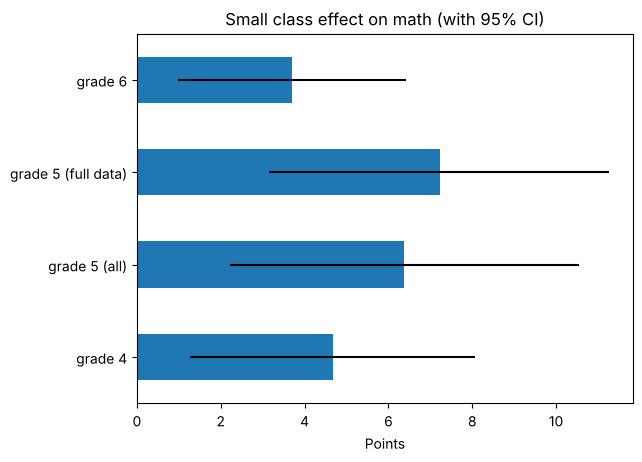

In [18]:
results["effect"].plot(kind="barh", xerr=[results["effect"] - results["CI low"],
                                          results["CI high"] - results["effect"]],
                       title="Small class effect on math (with 95% CI)")
plt.xlabel("Points")
plt.savefig("../figures/grade5_effect_estimates.png", dpi=150, bbox_inches="tight")
plt.show()

What we found:
- Grade 5 effect is about 6–7 points both ways, and significant.
- It's close to grade 4 (4.7) and grade 6 (3.7), the confidence intervals overlap a lot.
- So the missing data doesn't really change the result.

## 8. Conclusion

- The grade 5 drop is mostly missing records, not students leaving the study (most come back in grade 6, and whole schools are missing).
- The grade 5 sample is not representative (richer, higher scores), so we shouldn't compare grade 5 averages to other grades.
- The missing data is not connected to class type, so comparing small vs regular in grade 5 is OK.
- The small class effect in grade 5 is about the same with all students or only full data.

**Decision:** keep grade 5 in the analysis with a note about the sample, but base the main conclusion on grades 4, 6 and 8.

## Notes

- Open question: in grade 4 there are about 6,000 reading scores but only about 4,300 math scores. Why? Check later.